In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [23]:
# Load the Loan Prediction dataset
df = pd.read_csv("loan_data_set.csv")

# Display the first five records
print(df.head())

# Display dataset size
print("Dataset Shape:", df.shape)

    Loan_ID Gender Married Dependents     Education Self_Employed  \
0  LP001002   Male      No          0      Graduate            No   
1  LP001003   Male     Yes          1      Graduate            No   
2  LP001005   Male     Yes          0      Graduate           Yes   
3  LP001006   Male     Yes          0  Not Graduate            No   
4  LP001008   Male      No          0      Graduate            No   

   ApplicantIncome  CoapplicantIncome  LoanAmount  Loan_Amount_Term  \
0             5849                0.0         NaN             360.0   
1             4583             1508.0       128.0             360.0   
2             3000                0.0        66.0             360.0   
3             2583             2358.0       120.0             360.0   
4             6000                0.0       141.0             360.0   

   Credit_History Property_Area Loan_Status  
0             1.0         Urban           Y  
1             1.0         Rural           N  
2             1.0   

In [24]:
# Loan_ID is only an identification column
# It is not useful for predicting loan approval
df = df.drop(columns=["Loan_ID"])

# Display the remaining columns
print(df.columns)

Index(['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed',
       'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status'],
      dtype='str')


In [25]:
# X contains the input features
X = df.drop(columns=["Loan_Status"])

# y contains the target variable
# Y = 1 means loan approved
# N = 0 means loan rejected
y = df["Loan_Status"].map({"Y": 1, "N": 0})

# Display the features
print("Features:")
print(X.columns)

# Display target values
print("\nTarget values:")
print(y.value_counts())

Features:
Index(['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed',
       'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area'],
      dtype='str')

Target values:
Loan_Status
1    422
0    192
Name: count, dtype: int64


In [26]:
# Split dataset into 80% training and 20% testing data
# stratify keeps the class distribution similar in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display dataset sizes
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (491, 11)
Testing data: (123, 11)


In [27]:
# Find columns containing categorical/text data
categorical_cols = X_train.select_dtypes(
    include=["object", "str"]
).columns.tolist()

# Find columns containing numerical data
numerical_cols = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

print("Categorical columns:")
print(categorical_cols)

print("\nNumerical columns:")
print(numerical_cols)

Categorical columns:
['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Property_Area']

Numerical columns:
['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History']


In [28]:
# Numerical columns:
# Replace missing values with the median
numerical_transformer = SimpleImputer(
    strategy="median"
)

# Categorical columns:
# Replace missing values with the most frequent value
# Then convert categorical values into numerical form
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine numerical and categorical preprocessing
preprocessor = ColumnTransformer([
    ("num", numerical_transformer, numerical_cols),
    ("cat", categorical_transformer, categorical_cols)
])

# Apply preprocessing to training data
X_train = preprocessor.fit_transform(X_train)

# Apply the same preprocessing to testing data
X_test = preprocessor.transform(X_test)

print("Preprocessing completed!")
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Preprocessing completed!
Training shape: (491, 20)
Testing shape: (123, 20)


In [29]:
# Store results for different tree depths and number of trees
results = []

# Test different tree depths
for depth in [3, 5, 7, 10]:

    # Test different numbers of trees
    for n in [50, 100, 150, 200]:

        # Create Random Forest model
        model = RandomForestClassifier(
            n_estimators=n,
            max_depth=depth,
            random_state=42
        )

        # Train the model
        model.fit(X_train, y_train)

        # Predict on test data
        y_pred = model.predict(X_test)

        # Calculate evaluation metrics
        accuracy = accuracy_score(y_test, y_pred)
        precision = precision_score(y_test, y_pred)
        recall = recall_score(y_test, y_pred)
        f1 = f1_score(y_test, y_pred)

        # Store the results
        results.append([
            depth,
            n,
            accuracy,
            precision,
            recall,
            f1
        ])

# Convert results into a DataFrame
results_df = pd.DataFrame(
    results,
    columns=[
        "Tree Depth",
        "Number of Trees",
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ]
)

# Display the results
print(results_df)

    Tree Depth  Number of Trees  Accuracy  Precision    Recall  F1 Score
0            3               50  0.845528   0.823529  0.988235  0.898396
1            3              100  0.853659   0.831683  0.988235  0.903226
2            3              150  0.853659   0.831683  0.988235  0.903226
3            3              200  0.853659   0.831683  0.988235  0.903226
4            5               50  0.837398   0.815534  0.988235  0.893617
5            5              100  0.853659   0.831683  0.988235  0.903226
6            5              150  0.853659   0.831683  0.988235  0.903226
7            5              200  0.853659   0.831683  0.988235  0.903226
8            7               50  0.829268   0.826531  0.952941  0.885246
9            7              100  0.837398   0.828283  0.964706  0.891304
10           7              150  0.845528   0.830000  0.976471  0.897297
11           7              200  0.837398   0.828283  0.964706  0.891304
12          10               50  0.821138   0.83157

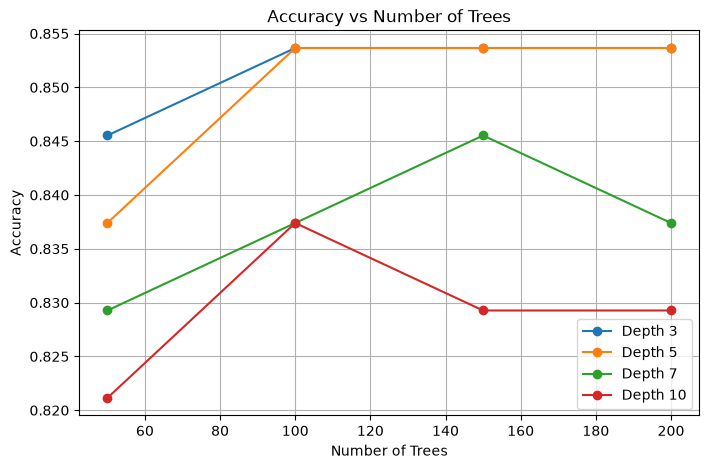

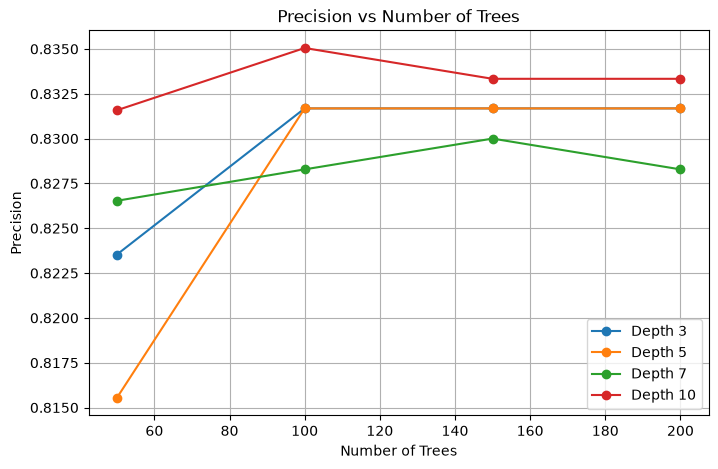

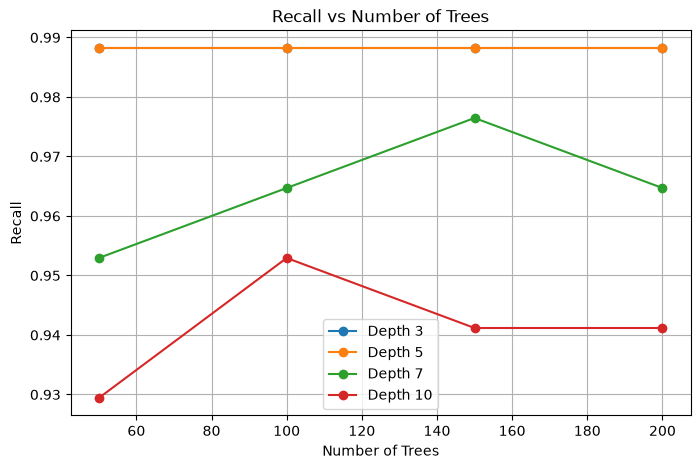

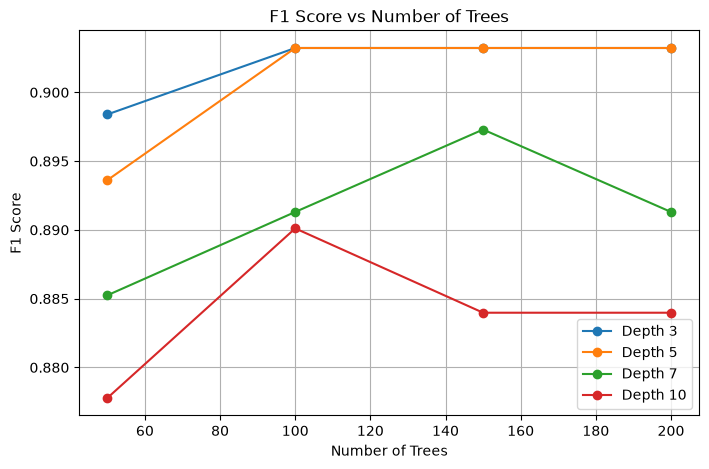

In [30]:
# List of evaluation metrics
metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

# Create a separate graph for each metric
for metric in metrics:

    # Create figure
    plt.figure(figsize=(8, 5))

    # Plot each tree depth
    for depth in [3, 5, 7, 10]:

        # Select results for this depth
        data = results_df[
            results_df["Tree Depth"] == depth
        ]

        # Plot metric against number of trees
        plt.plot(
            data["Number of Trees"],
            data[metric],
            marker="o",
            label="Depth " + str(depth)
        )

    # Labels
    plt.xlabel("Number of Trees")
    plt.ylabel(metric)

    # Title
    plt.title(metric + " vs Number of Trees")

    # Legend
    plt.legend()

    # Grid
    plt.grid()

    # Show graph
    plt.show()